# Graph Neural Networks from Scratch — Tutorial 8: Graph-Level Learning

### From node embeddings to one prediction per graph: classification and regression

*📺 Video on YouTube | 🐍 Python · PyTorch · PyTorch Geometric | Intermediate*

*Notebook repository: [github.com/rraj-io/GNN-Tutorials](https://github.com/rraj-io/GNN-Tutorials)*

---

## Series Roadmap

In Tutorial 1, we learned how graphs represent connected data through nodes, edges, adjacency matrices, and node features.

In Tutorials 2 and 3, we implemented and trained a **Graph Convolutional Network (GCN)** from scratch.

In Tutorial 4, we introduced **PyTorch Geometric (PyG)** and trained a GCN on the **Cora citation network**.

In Tutorial 5, we split a GNN layer into **message, aggregate, and update**. In Tutorial 6, we learned neighbour weights with **graph attention**. In Tutorial 7, we compared **aggregators**, sampled neighbourhoods, and tested GraphSAGE on **unseen nodes**.

In every one of these tutorials, the prediction target was a **node**: the topic of one paper. But many important questions are about a **whole graph**:

- Is this molecule mutagenic?
- What is the drag coefficient of this geometry?
- What is the total heat transfer through this mesh?
- Is this truss structure stable?

For these, we need **one prediction per graph**, even though graphs have different numbers of nodes. In this tutorial, we add one new step after message passing — a **readout** that turns a variable number of node embeddings into a single fixed-size graph embedding. We will build readouts from scratch, learn how PyG batches many small graphs, train a graph classifier on the **MUTAG** molecule dataset, and train a graph regressor on a synthetic engineering-style dataset.

| # | Tutorial | Focus | Status |
|---|---|---|---|
| 1 | Graph Fundamentals and Representations | nodes, edges, adjacency matrices, graph features | ✅ |
| 2 | Graph Convolutional Networks from Scratch | propagation, normalization, NumPy implementation | ✅ |
| 3 | Training a GCN with PyTorch | learnable parameters, backpropagation, node classification | ✅ |
| 4 | PyTorch Geometric and the Cora Dataset | PyG, real-world graph data, practical GCN implementation | ✅ |
| 5 | Message Passing Neural Networks | message, aggregate, update, custom GNN layers | ✅ |
| 6 | Graph Attention Networks (GAT) | learned attention, neighbour weighting, multi-head attention | ✅ |
| 7 | GraphSAGE and Advanced Aggregation | aggregators, neighbour sampling, mini-batches, inductive learning | ✅ |
| **8** | **Graph-Level Learning** | **readout, graph batching, graph classification and regression** | **📍 You are here** |
| 9 | GNNs for Mesh-Based Systems | mesh connectivity, geometric features, scientific data | Planned |
| 10 | GNNs for Scientific Machine Learning | surrogate modelling and engineering applications | Planned |

The goal is to progress from understanding graph representations and implementing GNNs from scratch to using practical tools for learning from complex connected systems, including computational meshes and physical systems.

---

In this tutorial, we will explore the essential components of graph-level learning:

- Node-level vs. edge-level vs. graph-level prediction.
- Why graph-level models need a **readout** (global pooling).
- Global mean, sum, and max pooling — implemented from scratch and verified against PyG.
- How PyG batches many graphs into one big disconnected graph with a `batch` vector.
- Loading and exploring the **MUTAG** molecule dataset.
- Training and evaluating a graph classifier — and comparing it with simple baselines.
- Comparing readouts fairly with repeated random splits.
- **Graph regression** on a synthetic dataset, and why sum and mean readouts behave differently for *extensive* and *intensive* quantities.
- Hierarchical pooling and graph-level prediction for engineering meshes.

We will begin with a few node embeddings small enough to pool by hand. Then, we will scale up to batches of molecules and engineering-style graphs.

## The learning process

Our workflow in this tutorial will follow this sequence:

```text
       Collection of Graphs
                |
                v
     Batch Graphs (batch vector)
                |
                v
   Message Passing → Node Embeddings
                |
                v
   Readout / Global Pooling   ← new
                |
                v
     One Embedding per Graph
                |
                v
      MLP Prediction Head
                |
                v
   Classification or Regression
                |
                v
  Evaluate vs. Baselines + Compare Readouts
```

Everything up to the node embeddings is what we already know from Tutorials 4–7. The new parts are the **readout**, the **batching of many graphs**, and the fact that each training example is now a **whole graph** rather than a node.

> **New to graph-level tasks?** Don't worry. A readout is just the aggregation from Tutorials 5 and 7, applied once more — but now every node of a graph sends its embedding to a single "graph node". We will implement it with the same `index_add_` and `scatter_reduce_` tools.
>
> If you're interested in scientific machine learning, CFD, or computational mechanics, pay attention to Part IX. Global engineering quantities come in two kinds: **extensive** (total heat flow, total mass, total length) and **intensive** (average temperature, density, mean stress). The choice between sum and mean readout should match the kind of quantity you predict.

**Let's move from predicting what each node is to predicting what the whole graph is.**

## 1. Why graph-level learning?

A GNN always starts by computing node embeddings. What changes between tasks is the **prediction head**:

| Task | Example | Prediction made from |
|---|---|---|
| Node-level | topic of a paper (Cora, Tutorials 4–7) | each node embedding $\mathbf h_v$ |
| Edge-level | will two users connect? | a pair of node embeddings $(\mathbf h_u,\mathbf h_v)$ |
| **Graph-level** | is this molecule mutagenic? | **one graph embedding** $\mathbf h_G$ |

For a graph $G=(V,E)$, the GNN produces node embeddings:

$$
\mathbf h_v^{(L)}=\operatorname{GNN}(G,\mathbf X)_v
$$

A **readout** combines them into one vector:

$$
\mathbf h_G=\operatorname{READOUT}\left(\{\mathbf h_v^{(L)}: v\in V\}\right)
$$

and a prediction head maps this vector to the output:

$$
\hat{\mathbf y}_G=f_\theta(\mathbf h_G)
$$

The readout has two requirements:

1. **Fixed size:** $\mathbf h_G$ has the same length for every graph, whatever its number of nodes.
2. **Permutation invariance:** relabelling the nodes must not change $\mathbf h_G$.

## 2. Setup

We use the same environment as Tutorials 4–7. If PyG is missing, the cell below installs it.

In [1]:
import sys
import subprocess

import torch
import torch.nn as nn
import torch.nn.functional as F

print("PyTorch:", torch.__version__)

try:
    import torch_geometric
except ImportError:
    print("PyTorch Geometric is not installed. Installing it now...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch-geometric"])
    import torch_geometric
    print("Installation complete.")

print("PyG:", torch_geometric.__version__)

torch.manual_seed(7)

PyTorch: 2.11.0+cu130


/home/rohit/venvs/py13env/lib64/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyG: 2.8.1


# Part I — Readout from scratch

## 3. Three simple readouts

The simplest readouts are the same three functions we compared as aggregators in Tutorial 7 — now applied over **all nodes of a graph** instead of over the neighbours of one node:

| Readout | Formula | Keeps graph size? |
|---|---|---|
| Sum | $\mathbf h_G=\sum_{v\in V}\mathbf h_v$ | ✅ grows with $\lvert V\rvert$ |
| Mean | $\mathbf h_G=\dfrac{1}{\lvert V\rvert}\sum_{v\in V}\mathbf h_v$ | ❌ |
| Max | $\mathbf h_G[k]=\max_{v\in V}\mathbf h_v[k]$ | ❌ |

All three are permutation-invariant and return a vector of the same length as one node embedding.

## 4. Pool four node embeddings by hand

Each row below is the embedding of one node in a single graph.

In [2]:
# One graph with four nodes, each with a 3-dimensional embedding
node_embeddings = torch.tensor([
    [1.0, 0.0, 2.0],   # node 0
    [3.0, 1.0, 0.0],   # node 1
    [2.0, 4.0, 1.0],   # node 2
    [0.0, 2.0, 3.0],   # node 3
])

print("Sum :", node_embeddings.sum(dim=0))
print("Mean:", node_embeddings.mean(dim=0))
print("Max :", node_embeddings.max(dim=0).values)

Sum : tensor([6., 7., 6.])
Mean: tensor([1.5000, 1.7500, 1.5000])
Max : tensor([3., 4., 3.])


## 5. The output size does not depend on the number of nodes

Let's add a fifth node and pool again. Every readout still returns a vector of length 3.

In [3]:
extra_node = torch.tensor([[5.0, 1.0, 2.0]])
expanded = torch.cat([node_embeddings, extra_node], dim=0)

for name, fn in [("Sum ", lambda h: h.sum(0)), ("Mean", lambda h: h.mean(0)), ("Max ", lambda h: h.max(0).values)]:
    print(f"{name}: 4 nodes -> {fn(node_embeddings).tolist()}   5 nodes -> {fn(expanded).tolist()}")

Sum : 4 nodes -> [6.0, 7.0, 6.0]   5 nodes -> [11.0, 8.0, 8.0]
Mean: 4 nodes -> [1.5, 1.75, 1.5]   5 nodes -> [2.200000047683716, 1.600000023841858, 1.600000023841858]
Max : 4 nodes -> [3.0, 4.0, 3.0]   5 nodes -> [5.0, 4.0, 3.0]


## 🧪 Hands-on Exercise 1

Build a second graph by **duplicating** every node of `node_embeddings` (8 nodes in total, each embedding appearing twice).

1. Which readouts give the **same** result for the original and the duplicated graph?
2. Which readout can tell them apart?
3. Connect your answer to the aggregator table from Tutorial 7, Section 6.

In [4]:
# TODO: compare readouts for a graph and its duplicated version.

# doubled = torch.cat([node_embeddings, node_embeddings], dim=0)
# print(node_embeddings.sum(0), doubled.sum(0))
# print(node_embeddings.mean(0), doubled.mean(0))
# print(node_embeddings.max(0).values, doubled.max(0).values)

# Part II — Batching many graphs

## 6. One big disconnected graph

On Cora, there was only one graph. Now our dataset contains **many small graphs**, and we want to process several of them in one forward pass.

PyG's trick: put all graphs of a mini-batch into **one big graph with no edges between them**.

```text
graph 0         graph 1      graph 2              one batched graph
 0──1            0──1         0──1                 0──1   3──4   5──6
  \ /                          │          ──▶       \ /           │
   2                           2                     2            7

batch = [0, 0, 0,   1, 1,   2, 2, 2]   ← which graph each node belongs to
```

- Node features are **stacked** row by row.
- Edge indices are **shifted** by the number of nodes in the earlier graphs, so they still point to the right rows.
- A **`batch` vector** records which graph each node came from.

Because there are no edges between graphs, message passing never mixes information between them. Our GNN layers from Tutorials 4–7 work on the batched graph **without any changes**.

## 7. A readout for a batch: aggregate by graph

A batched readout is exactly the aggregation from Tutorial 7 — with the `batch` vector playing the role of the destination index:

| Tutorial 7: neighbour aggregation | Tutorial 8: batched readout |
|---|---|
| `index_add_(0, dst, x[src])` | `index_add_(0, batch, x)` |
| one row per **destination node** | one row per **graph** |

In [4]:
def global_pool(x, batch, how="mean"):
    """Readout: combine node embeddings into one embedding per graph."""
    num_graphs = int(batch.max()) + 1
    num_features = x.size(1)

    if how in ("sum", "mean"):
        out = torch.zeros(num_graphs, num_features, dtype=x.dtype, device=x.device)
        out.index_add_(0, batch, x)
        if how == "mean":
            counts = torch.zeros(num_graphs, 1, dtype=x.dtype, device=x.device)
            counts.index_add_(0, batch, torch.ones(batch.numel(), 1, dtype=x.dtype, device=x.device))
            out = out / counts
        return out

    if how == "max":
        out = torch.full((num_graphs, num_features), -torch.inf, dtype=x.dtype, device=x.device)
        out.scatter_reduce_(0, batch[:, None].expand(-1, num_features), x, reduce="amax", include_self=True)
        return out

    raise ValueError(f"Unknown readout: {how}")

# Eight node embeddings from three graphs
x = torch.tensor([
    [1.0, 0.0], [3.0, 2.0], [2.0, 1.0],   # graph 0
    [4.0, 1.0], [2.0, 5.0],               # graph 1
    [0.0, 3.0], [1.0, 2.0], [2.0, 4.0],   # graph 2
])
batch = torch.tensor([0, 0, 0, 1, 1, 2, 2, 2])

for how in ["mean", "sum", "max"]:
    print(f"{how.upper()} readout:\n{global_pool(x, batch, how)}\n")

MEAN readout:
tensor([[2., 1.],
        [3., 3.],
        [1., 3.]])

SUM readout:
tensor([[6., 3.],
        [6., 6.],
        [3., 9.]])

MAX readout:
tensor([[3., 2.],
        [4., 5.],
        [2., 4.]])



## 8. Verify against PyG's global pooling

PyG provides the same three readouts as `global_mean_pool`, `global_add_pool`, and `global_max_pool`. As in every tutorial, we check them against our version.

In [5]:
from torch_geometric.nn import global_mean_pool, global_add_pool, global_max_pool

pyg_pools = {"mean": global_mean_pool, "sum": global_add_pool, "max": global_max_pool}

for how, pyg_fn in pyg_pools.items():
    diff = (global_pool(x, batch, how) - pyg_fn(x, batch)).abs().max().item()
    print(f"{how:4s}: max difference = {diff}")

mean: max difference = 0.0
sum : max difference = 0.0
max : max difference = 0.0


## 9. How PyG builds a batch

Let's build three small graphs as `Data` objects and let PyG batch them. Watch the edge indices of graphs 1 and 2: they are shifted by the number of nodes before them.

In [6]:
from torch_geometric.data import Data, Batch

g0 = Data(x=torch.randn(3, 2), edge_index=torch.tensor([[0, 1, 1, 2, 0, 2], [1, 0, 2, 1, 2, 0]]), y=torch.tensor([0]))
g1 = Data(x=torch.randn(2, 2), edge_index=torch.tensor([[0, 1], [1, 0]]), y=torch.tensor([1]))
g2 = Data(x=torch.randn(3, 2), edge_index=torch.tensor([[0, 2], [2, 0]]), y=torch.tensor([0]))

batched = Batch.from_data_list([g0, g1, g2])

print(batched)
print("Number of graphs:", batched.num_graphs)
print("batch vector:   ", batched.batch.tolist())
print("Graph labels y: ", batched.y.tolist())
print("edge_index:\n", batched.edge_index)

DataBatch(x=[8, 2], edge_index=[2, 10], y=[3], batch=[8], ptr=[4])
Number of graphs: 3
batch vector:    [0, 0, 0, 1, 1, 2, 2, 2]
Graph labels y:  [0, 1, 0]
edge_index:
 tensor([[0, 1, 1, 2, 0, 2, 3, 4, 5, 7],
        [1, 0, 2, 1, 2, 0, 4, 3, 7, 5]])


Graph 1's edge `0 → 1` became `3 → 4`, and graph 2's edge `0 → 2` became `5 → 7`. The labels `y` now have **one entry per graph**, not per node.

## 🧪 Hands-on Exercise 2

1. Why does `global_mean_pool(x, batch)` return 3 rows and not 8?
2. What would happen if `batch` contained only zeros?
3. Use `batched.to_data_list()` to recover the original graphs. Are the edge indices shifted back?

In [8]:
# TODO: explore batching.

# print(global_mean_pool(x, torch.zeros(8, dtype=torch.long)))
# for g in batched.to_data_list():
#     print(g.edge_index)

# Part III — The MUTAG dataset

## 10. What is MUTAG?

MUTAG is a classic graph-classification benchmark from the TUDataset collection:

- **Graph:** a nitroaromatic chemical compound (a molecule)
- **Node:** an atom
- **Edge:** a chemical bond
- **Node features:** one-hot atom type (7 types: C, N, O, F, I, Cl, Br)
- **Graph label:** whether the compound is mutagenic (2 classes)

Our task is to predict **one label per molecule**. This is graph classification, not node classification.

MUTAG is small (188 graphs), which makes it fast for teaching — but also means results vary noticeably between random splits. We will take that seriously in Part VII.

In [7]:
from torch_geometric.datasets import TUDataset

# The dataset is downloaded on first use.
dataset = TUDataset(root="data/TUDataset", name="MUTAG")

print(dataset)
print("Number of graphs:", len(dataset))
print("Node features:", dataset.num_node_features)
print("Classes:", dataset.num_classes)

Processing...
Done!


MUTAG(188)
Number of graphs: 188
Node features: 7
Classes: 2


## 11. Inspect individual graphs

Each graph is a `Data` object, just like Cora — but much smaller, and with a **single** label in `y`.

In [8]:
atom_types = ["C", "N", "O", "F", "I", "Cl", "Br"]

for idx in [0, 1, 2]:
    graph = dataset[idx]
    atoms = [atom_types[i] for i in graph.x.argmax(dim=1).tolist()]
    print(f"Graph {idx}: {graph.num_nodes} atoms, {graph.num_edges // 2} bonds, label = {int(graph.y)}")
    print("   atoms:", " ".join(atoms))

Graph 0: 17 atoms, 19 bonds, label = 1
   atoms: C C C C C C C C C C C C C C N O O
Graph 1: 13 atoms, 14 bonds, label = 0
   atoms: C C C C C C N C C C N O O
Graph 2: 13 atoms, 14 bonds, label = 0
   atoms: C C C C C C C N C C N O O


## 12. Graph sizes and class balance

A graph dataset is not a rectangular table: every graph has a different number of nodes and edges. Let's summarise them, and check the **class balance** — it decides what accuracy a trivial model would get.

Atoms per molecule: min = 10, mean = 17.9, max = 28
Class counts: {0: 63, 1: 125}
Majority-class accuracy: 0.665


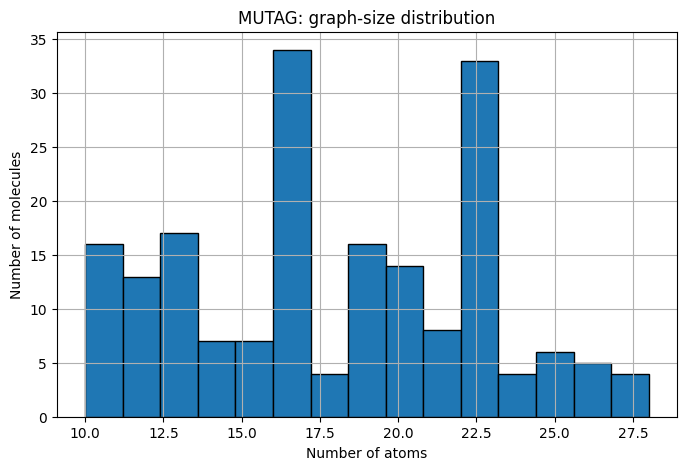

In [9]:
import matplotlib.pyplot as plt
from collections import Counter

num_nodes = [g.num_nodes for g in dataset]
labels = [int(g.y) for g in dataset]
class_counts = Counter(labels)

print(f"Atoms per molecule: min = {min(num_nodes)}, mean = {sum(num_nodes) / len(num_nodes):.1f}, max = {max(num_nodes)}")
print("Class counts:", dict(sorted(class_counts.items())))
print(f"Majority-class accuracy: {max(class_counts.values()) / len(dataset):.3f}")

plt.figure(figsize=(8, 5))
plt.hist(num_nodes, bins=15, edgecolor="black")
plt.xlabel("Number of atoms")
plt.ylabel("Number of molecules")
plt.title("MUTAG: graph-size distribution")
plt.grid(True)
plt.show()

About two thirds of the molecules belong to class 1. A model that **always predicts class 1** already reaches about 66% accuracy. Any graph classifier must beat this **majority baseline** to be useful.

## 13. Train, validation, and test splits

On Cora, we used masks over nodes. Now each example is a whole graph, so we split the **list of graphs**: 70% train, 15% validation, 15% test.

In [10]:
from torch.utils.data import random_split

split_seed = 42
n_total = len(dataset)
n_train = int(0.70 * n_total)
n_val = int(0.15 * n_total)
n_test = n_total - n_train - n_val

train_dataset, val_dataset, test_dataset = random_split(
    dataset, [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(split_seed),
)

print("Training graphs:", len(train_dataset))
print("Validation graphs:", len(val_dataset))
print("Test graphs:", len(test_dataset))

Training graphs: 131
Validation graphs: 28
Test graphs: 29


With only 29 test graphs, **each graph is worth about 3.4 percentage points** of test accuracy. Keep this in mind when comparing numbers.

## 14. Data loaders

PyG's `DataLoader` builds batches exactly as in Section 9 — it calls `Batch.from_data_list` for us.

In [11]:
from torch_geometric.loader import DataLoader

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

batch = next(iter(train_loader))
print(batch)
print("Graphs in batch:", batch.num_graphs)
print("Nodes in batch: ", batch.num_nodes)
print("batch vector (first 30):", batch.batch[:30].tolist())
print("Labels shape:", tuple(batch.y.shape))

DataBatch(edge_index=[2, 1248], x=[569, 7], edge_attr=[1248, 4], y=[32], batch=[569], ptr=[33])
Graphs in batch: 32
Nodes in batch:  569
batch vector (first 30): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Labels shape: (32,)


# Part IV — Build a graph-level GNN

## 15. The model

The model has three stages:

```text
 x, edge_index ──▶ GCNConv ─ ReLU ─ GCNConv ─ ReLU ──▶ node embeddings   [num_nodes, H]
                                                            │
                                        batch ──▶  readout (mean / sum / max)
                                                            │
                                                     graph embeddings    [num_graphs, H]
                                                            │
                                                    MLP head ──▶ logits  [num_graphs, C]
```

1. **Node encoder:** two `GCNConv` layers, as in Tutorial 4.
2. **Readout:** one of our three global pooling functions.
3. **Prediction head:** a small MLP that maps the graph embedding to class logits.

The only change to the forward signature is the extra `batch` argument.

In [12]:
from torch_geometric.nn import GCNConv

class GraphGCN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, readout="mean", dropout=0.5):
        super().__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.readout = readout
        self.head = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, output_dim),
        )

    def forward(self, x, edge_index, batch):
        # 1. Node encoder
        x = F.relu(self.conv1(x, edge_index))
        x = F.relu(self.conv2(x, edge_index))

        # 2. Readout: one embedding per graph
        h_graph = global_pool(x, batch, self.readout)

        # 3. Prediction head: one logit vector per graph
        return self.head(h_graph)

We use our own `global_pool` from Section 7. You could replace it with `global_mean_pool` and friends — Section 8 showed they are identical.

## 16. Create the model and run a forward pass

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = GraphGCN(
    input_dim=dataset.num_node_features,
    hidden_dim=64,
    output_dim=dataset.num_classes,
    readout="mean",
).to(device)

print(model)
print("Device:", device)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

GraphGCN(
  (conv1): GCNConv(7, 64)
  (conv2): GCNConv(64, 64)
  (head): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=64, out_features=2, bias=True)
  )
)
Device: cpu
Trainable parameters: 8962


In [14]:
sample_batch = next(iter(train_loader)).to(device)

model.eval()
with torch.no_grad():
    logits = model(sample_batch.x, sample_batch.edge_index, sample_batch.batch)

print("Logits shape:", tuple(logits.shape))
print("Expected:    ", (sample_batch.num_graphs, dataset.num_classes))

Logits shape: (32, 2)
Expected:     (32, 2)


One row per **graph**, not per node. That is the whole difference from Tutorials 4–7.

## 17. Evaluation function

On Cora, `accuracy(model, data, mask)` ran one forward pass on the whole graph. Now the data comes in batches, so we loop over a loader and count correct graphs.

In [15]:
@torch.no_grad()
def accuracy(model, loader):
    model.eval()
    correct = total = 0
    for batch in loader:
        batch = batch.to(device)
        logits = model(batch.x, batch.edge_index, batch.batch)
        correct += int((logits.argmax(dim=1) == batch.y).sum())
        total += batch.num_graphs
    return correct / total

print("Train accuracy (untrained):", round(accuracy(model, train_loader), 4))
print("Validation accuracy (untrained):", round(accuracy(model, val_loader), 4))

Train accuracy (untrained): 0.7099
Validation accuracy (untrained): 0.6071


# Part V — Train the graph classifier

## 18. Full training loop

The loop is the same as in Tutorials 4–7, with one difference: each epoch iterates over **mini-batches of graphs**. As in Tutorial 7's mini-batch training, there are several optimizer updates per epoch.

```text
for each batch of graphs:  forward → loss → backward → optimizer step
then:                      validate → keep best checkpoint
```

`CrossEntropyLoss` compares one logit vector with one label **per graph**.

In [16]:
import copy

torch.manual_seed(7)
model = GraphGCN(dataset.num_node_features, 64, dataset.num_classes, readout="mean").to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
criterion = nn.CrossEntropyLoss()

history = {"loss": [], "train_acc": [], "val_acc": []}
best_val_acc, best_state, best_epoch = 0.0, None, 0
epochs = 100

for epoch in range(1, epochs + 1):
    model.train()
    epoch_loss = 0.0
    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        logits = model(batch.x, batch.edge_index, batch.batch)
        loss = criterion(logits, batch.y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * batch.num_graphs

    train_acc = accuracy(model, train_loader)
    val_acc = accuracy(model, val_loader)

    history["loss"].append(epoch_loss / len(train_dataset))
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc, best_epoch = val_acc, epoch
        best_state = copy.deepcopy(model.state_dict())

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | Loss {history['loss'][-1]:.4f} | "
            f"Train {train_acc:.4f} | Val {val_acc:.4f}"
        )

print(f"\nBest validation accuracy: {best_val_acc:.4f} (epoch {best_epoch})")

Epoch 001 | Loss 0.6562 | Train 0.7099 | Val 0.6071
Epoch 010 | Loss 0.5732 | Train 0.7099 | Val 0.6071
Epoch 020 | Loss 0.4882 | Train 0.7252 | Val 0.6071
Epoch 030 | Loss 0.4949 | Train 0.7710 | Val 0.6786
Epoch 040 | Loss 0.5127 | Train 0.7939 | Val 0.6786
Epoch 050 | Loss 0.4736 | Train 0.7863 | Val 0.6786
Epoch 060 | Loss 0.5068 | Train 0.7863 | Val 0.6786
Epoch 070 | Loss 0.4815 | Train 0.7710 | Val 0.7143
Epoch 080 | Loss 0.5129 | Train 0.7863 | Val 0.7143
Epoch 090 | Loss 0.4536 | Train 0.7939 | Val 0.7143
Epoch 100 | Loss 0.4738 | Train 0.7786 | Val 0.7143

Best validation accuracy: 0.7857 (epoch 91)


## 19. Plot the learning curves

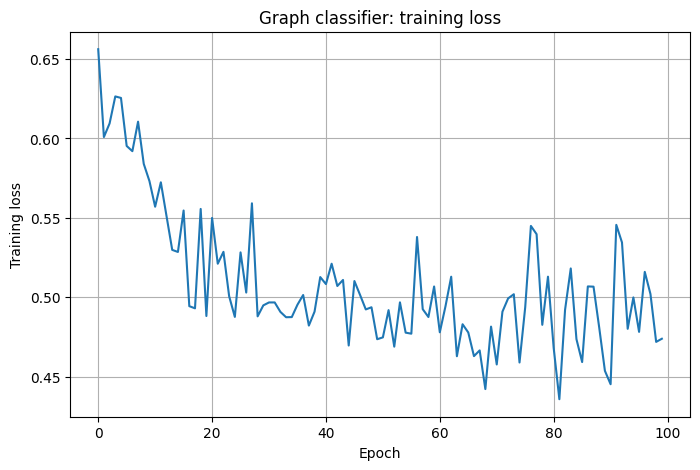

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Graph classifier: training loss")
plt.grid(True)
plt.show()

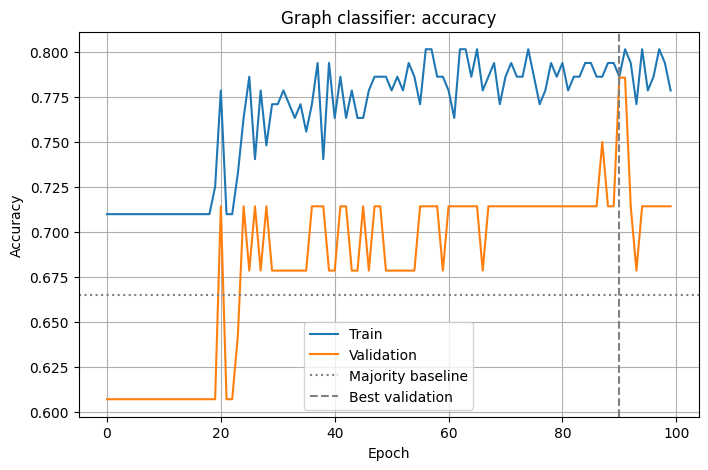

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_acc"], label="Train")
plt.plot(history["val_acc"], label="Validation")
plt.axhline(max(class_counts.values()) / len(dataset), color="gray", linestyle=":", label="Majority baseline")
plt.axvline(best_epoch - 1, color="gray", linestyle="--", label="Best validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Graph classifier: accuracy")
plt.legend()
plt.grid(True)
plt.show()

With only 28 validation graphs, the validation curve moves in steps of about 3.6 percentage points, and it is much noisier than on Cora. That is a property of the small dataset, not a bug in the training loop.

# Part VI — Final test evaluation

## 20. Evaluate the best checkpoint on the test graphs

In [19]:
model.load_state_dict(best_state)

test_acc = accuracy(model, test_loader)
test_labels = torch.cat([b.y for b in test_loader])
majority_test_acc = (test_labels == 1).float().mean().item()

print(f"Test graphs: {len(test_dataset)}")
print(f"Majority-class baseline (always predict 1): {majority_test_acc:.4f}")
print(f"Graph GCN test accuracy:                    {test_acc:.4f}")

Test graphs: 29
Majority-class baseline (always predict 1): 0.5172
Graph GCN test accuracy:                    0.6897


We now have a complete graph-level pipeline:

$$
\text{Graphs}\rightarrow\text{Batch}\rightarrow\text{Message passing}\rightarrow\underbrace{\text{Readout}}_{\text{new}}\rightarrow\text{MLP head}\rightarrow\text{One prediction per graph}
$$

Always report the baseline next to the model. A test accuracy on its own says little when two thirds of the molecules belong to one class.

# Part VII — What happens inside a graph-level model?

## 21. Visualise the graph embeddings

The readout turns each molecule into a 64-dimensional vector $\mathbf h_G$. Let's project these vectors to 2D with PCA and colour them by label. If the model has learned something useful, the two classes should occupy different regions.

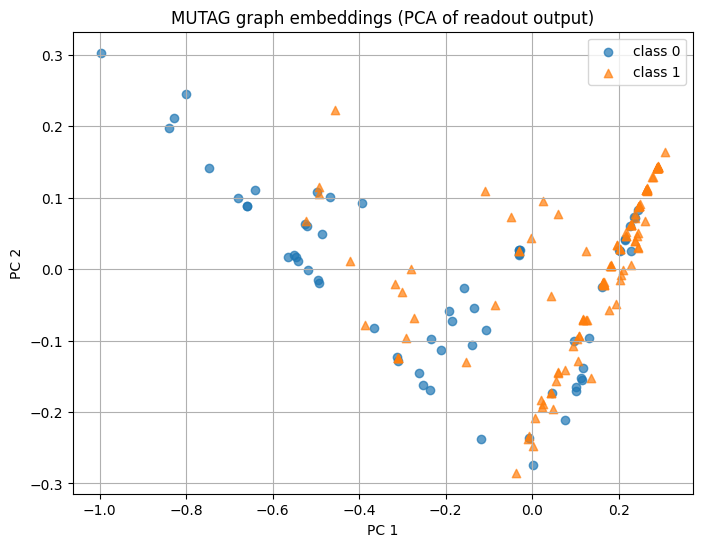

In [20]:
@torch.no_grad()
def graph_embeddings(model, loader):
    model.eval()
    embs, ys = [], []
    for batch in loader:
        batch = batch.to(device)
        h = F.relu(model.conv1(batch.x, batch.edge_index))
        h = F.relu(model.conv2(h, batch.edge_index))
        embs.append(global_pool(h, batch.batch, model.readout).cpu())
        ys.append(batch.y.cpu())
    return torch.cat(embs), torch.cat(ys)

all_loader = DataLoader(dataset, batch_size=64)
H, y_all = graph_embeddings(model, all_loader)

# PCA with torch: project onto the top-2 principal directions
H_centered = H - H.mean(dim=0)
_, _, V = torch.pca_lowrank(H_centered, q=2)
H_2d = H_centered @ V[:, :2]

plt.figure(figsize=(8, 6))
for label, marker in [(0, "o"), (1, "^")]:
    pts = H_2d[y_all == label]
    plt.scatter(pts[:, 0], pts[:, 1], marker=marker, alpha=0.7, label=f"class {label}")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.title("MUTAG graph embeddings (PCA of readout output)")
plt.legend()
plt.grid(True)
plt.show()

Look at whether the two classes occupy different regions of the plot. Where they overlap, the MLP head has little chance of separating them — those molecules are likely to be misclassified. The head only has to draw a boundary in this embedding space; all the "graph understanding" happens before the readout.

## 22. A fair comparison of readouts

Which readout works best on MUTAG? A single split with 29 test graphs cannot answer this reliably — one or two graphs change the ranking.

Instead, we repeat the experiment on **5 different random splits** and report the mean and standard deviation. We also add two baselines:

- **Majority class** — always predict the most common label.
- **No message passing** — the same MLP head applied to the mean of the raw one-hot atom features. This is a "bag of atoms" model: it knows which atoms a molecule contains, but not how they are bonded.

If the GNN cannot beat the bag-of-atoms baseline, graph structure is not helping.

In [24]:
import statistics

class BagOfAtoms(nn.Module):
    """Baseline: readout on raw features, no message passing."""
    def __init__(self, input_dim, hidden_dim, output_dim, dropout=0.5):
        super().__init__()
        self.head = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(hidden_dim, output_dim))

    def forward(self, x, edge_index, batch):
        return self.head(global_pool(x, batch, "mean"))

def fit(model, train_loader, val_loader, epochs=100, lr=0.01, weight_decay=5e-4):
    """Train with best-validation checkpointing (same loop as Section 18)."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    best_val, best_state = -1.0, None
    for _ in range(epochs):
        model.train()
        for batch in train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            loss = criterion(model(batch.x, batch.edge_index, batch.batch), batch.y)
            loss.backward()
            optimizer.step()
        val = accuracy(model, val_loader)
        if val > best_val:
            best_val, best_state = val, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model

def make_loaders(seed):
    tr, va, te = random_split(dataset, [n_train, n_val, n_test],
                              generator=torch.Generator().manual_seed(seed))
    return (DataLoader(tr, batch_size=32, shuffle=True),
            DataLoader(va, batch_size=32), DataLoader(te, batch_size=32))

builders = {
    "Bag of atoms (no MP)": lambda: BagOfAtoms(dataset.num_node_features, 64, dataset.num_classes),
    "GCN + mean readout":   lambda: GraphGCN(dataset.num_node_features, 64, dataset.num_classes, "mean"),
    "GCN + sum readout":    lambda: GraphGCN(dataset.num_node_features, 64, dataset.num_classes, "sum"),
    "GCN + max readout":    lambda: GraphGCN(dataset.num_node_features, 64, dataset.num_classes, "max"),
}

split_seeds = [0, 1, 2, 3, 4]
results = {"Majority class": []}
results.update({name: [] for name in builders})

for seed in split_seeds:
    tr_loader, va_loader, te_loader = make_loaders(seed)
    te_y = torch.cat([b.y for b in te_loader])
    results["Majority class"].append((te_y == 1).float().mean().item())
    for name, build in builders.items():
        torch.manual_seed(seed)
        m = fit(build().to(device), tr_loader, va_loader)
        results[name].append(accuracy(m, te_loader))

print(f"{'Model':22s} | test accuracy over {len(split_seeds)} splits")
print("-" * 52)
for name, accs in results.items():
    print(f"{name:22s} | {statistics.mean(accs):.3f} ± {statistics.stdev(accs):.3f}")

Model                  | test accuracy over 5 splits
----------------------------------------------------
Majority class         | 0.628 ± 0.062
Bag of atoms (no MP)   | 0.669 ± 0.093
GCN + mean readout     | 0.690 ± 0.081
GCN + sum readout      | 0.759 ± 0.088
GCN + max readout      | 0.690 ± 0.065


Read this table with the standard deviations in mind. Differences smaller than about one standard deviation are not reliable on a dataset of this size.

Questions to discuss:
- Does message passing beat the bag-of-atoms baseline? By how much, compared with the spread between splits?
- Sum readout keeps the molecule's size; mean and max do not. Could size be a useful signal for mutagenicity?
- Xu et al. (2019) showed that **sum** readout is the most expressive of the three — it can distinguish multisets that mean and max cannot (recall Exercise 1). Does more expressive always mean better accuracy on a small dataset?

# Part VIII — Inspect predictions

## 23. Compare predicted and true labels on test graphs

We return to the model from Part V and look at individual test molecules.

In [25]:
model.eval()
rows = []
with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)
        probs = torch.softmax(model(batch.x, batch.edge_index, batch.batch), dim=1)
        sizes = torch.bincount(batch.batch, minlength=batch.num_graphs)
        for p, y, n in zip(probs, batch.y, sizes):
            rows.append((int(n), int(y), int(p.argmax()), float(p.max())))

print("Graph | Atoms | True | Predicted | Confidence")
print("----------------------------------------------")
for i, (n, y, pred, conf) in enumerate(rows[:15]):
    flag = "" if y == pred else "  ✗"
    print(f"{i:5d} | {n:5d} | {y:4d} | {pred:9d} | {conf:10.3f}{flag}")

Graph | Atoms | True | Predicted | Confidence
----------------------------------------------
    0 |    19 |    1 |         1 |      0.590
    1 |    22 |    0 |         1 |      0.718  ✗
    2 |    26 |    1 |         1 |      0.806
    3 |    23 |    1 |         1 |      0.876
    4 |    11 |    0 |         1 |      0.764  ✗
    5 |    11 |    0 |         1 |      0.681  ✗
    6 |    13 |    0 |         0 |      0.561
    7 |    12 |    0 |         1 |      0.682  ✗
    8 |    14 |    0 |         0 |      0.500
    9 |    15 |    1 |         1 |      0.829
   10 |    13 |    0 |         1 |      0.804  ✗
   11 |    12 |    0 |         0 |      0.769
   12 |    11 |    0 |         0 |      0.642
   13 |    23 |    1 |         0 |      0.654  ✗
   14 |    13 |    0 |         0 |      0.678


## 24. Are errors related to molecule size?

In [26]:
wrong = [n for n, y, p, _ in rows if y != p]
right = [n for n, y, p, _ in rows if y == p]

print(f"Correct predictions:   {len(right):2d} graphs, mean size = {statistics.mean(right):.1f} atoms")
if wrong:
    print(f"Incorrect predictions: {len(wrong):2d} graphs, mean size = {statistics.mean(wrong):.1f} atoms")
else:
    print("No incorrect predictions on this split.")

Correct predictions:   20 graphs, mean size = 18.2 atoms
Incorrect predictions:  9 graphs, mean size = 15.0 atoms


With so few test graphs, treat this as a hint rather than a conclusion. On a larger dataset, the same analysis can reveal whether a model struggles with unusually large or small graphs — an important check before applying it to meshes of a different resolution.

# 🧪 Hands-on Exercise 3 — Hidden dimension and depth

Try `hidden_dim` of 16, 32, 64, and 128, and models with 2, 3, and 4 `GCNConv` layers. Use the 5-split protocol from Section 22.

Does a larger or deeper model generalise better on 188 molecules?

In [26]:
# TODO: vary hidden_dim and depth, and evaluate over 5 splits.

# for hidden in [16, 32, 64, 128]:
#     accs = []
#     for seed in split_seeds:
#         tr_loader, va_loader, te_loader = make_loaders(seed)
#         torch.manual_seed(seed)
#         m = fit(GraphGCN(dataset.num_node_features, hidden, dataset.num_classes).to(device), tr_loader, va_loader)
#         accs.append(accuracy(m, te_loader))
#     print(hidden, statistics.mean(accs))

# 🧪 Hands-on Exercise 4 — Swap the node encoder

Replace `GCNConv` with `SAGEConv` (Tutorial 7) or `GATConv` (Tutorial 6). Only the node encoder changes — the readout and head stay the same.

Which encoder works best on MUTAG with the 5-split protocol?

In [27]:
# TODO: build a graph-level model with a different encoder.

# from torch_geometric.nn import SAGEConv
# class GraphSAGEClassifier(GraphGCN):
#     def __init__(self, input_dim, hidden_dim, output_dim, readout="sum", dropout=0.5):
#         super().__init__(input_dim, hidden_dim, output_dim, readout, dropout)
#         self.conv1 = SAGEConv(input_dim, hidden_dim)
#         self.conv2 = SAGEConv(hidden_dim, hidden_dim)

# 🧪 Hands-on Exercise 5 — Concatenate readouts

Instead of choosing one readout, concatenate all three: $\mathbf h_G=[\text{mean}\Vert\text{sum}\Vert\text{max}]$. The head's input size becomes $3H$.

Does combining readouts help? Remember to compare with the standard deviations from Section 22.

In [28]:
# TODO: implement a multi-readout model.

# h_graph = torch.cat([global_pool(x, batch, "mean"),
#                      global_pool(x, batch, "sum"),
#                      global_pool(x, batch, "max")], dim=1)

# Part IX — Graph regression: extensive vs. intensive quantities

## 25. From classification to regression

For regression, only the **head** and the **loss** change:

| | Classification | Regression |
|---|---|---|
| Output size | number of classes | 1 (or number of targets) |
| Loss | `CrossEntropyLoss` | `MSELoss` |
| Metric | accuracy | MAE, $R^2$ |

$$
\hat y_G=f_\theta(\mathbf h_G),\qquad \mathcal L_{\text{MSE}}=\frac{1}{N}\sum_{i=1}^{N}\left(y_i-\hat y_i\right)^2
$$

MUTAG has no continuous targets, so we build a small **synthetic engineering-style dataset** where we know the exact answer.

## 26. A synthetic dataset: random networks of rods

Each graph is a random 2D network, like a truss or a mesh patch:

- **Nodes:** between 10 and 50 points placed uniformly in a square. The square grows with the number of points, so the **density stays constant** — a larger network covers a larger area, just as a larger mesh covers a larger domain at the same resolution.
- **Edges:** two points are connected if they are closer than $r=0.3$.
- **Node features:** the $(x, y)$ coordinates.

We define two graph-level targets:

| Target | Definition | Type |
|---|---|---|
| Total length | $L=\sum_{\text{edges}}\lVert\mathbf p_i-\mathbf p_j\rVert$ | **extensive** — grows with the size of the graph (like total mass or total heat flow) |
| Mean length | $\bar\ell=L/\lvert E\rvert$ | **intensive** — does not grow with size (like density or average temperature) |

In [27]:
def random_rod_network(num_nodes, radius=0.3, density=25.0):
    side = (num_nodes / density) ** 0.5                  # constant points per unit area
    pos = torch.rand(num_nodes, 2) * side
    dist = torch.cdist(pos, pos)
    adj = (dist < radius) & ~torch.eye(num_nodes, dtype=torch.bool)
    edge_index = adj.nonzero().t()                       # both directions
    lengths = dist[edge_index[0], edge_index[1]]
    total_length = lengths.sum() / 2                     # each edge counted twice
    num_edges = edge_index.size(1) // 2
    mean_length = total_length / max(num_edges, 1)
    return Data(x=pos, edge_index=edge_index,
                y_total=total_length.view(1), y_mean=mean_length.view(1))

torch.manual_seed(0)
rod_graphs = [random_rod_network(int(torch.randint(10, 51, (1,)))) for _ in range(1200)]
rod_graphs = [g for g in rod_graphs if g.edge_index.size(1) > 0]

print("Graphs:", len(rod_graphs))
print("Example:", rod_graphs[0])
sizes = torch.tensor([g.num_nodes for g in rod_graphs], dtype=torch.float)
totals = torch.cat([g.y_total for g in rod_graphs])
means = torch.cat([g.y_mean for g in rod_graphs])
print(f"Correlation with graph size: total length = {torch.corrcoef(torch.stack([sizes, totals]))[0, 1]:.2f}, "
      f"mean length = {torch.corrcoef(torch.stack([sizes, means]))[0, 1]:.2f}")

Graphs: 1200
Example: Data(x=[11, 2], edge_index=[2, 56], y_total=[1], y_mean=[1])
Correlation with graph size: total length = 0.95, mean length = 0.20


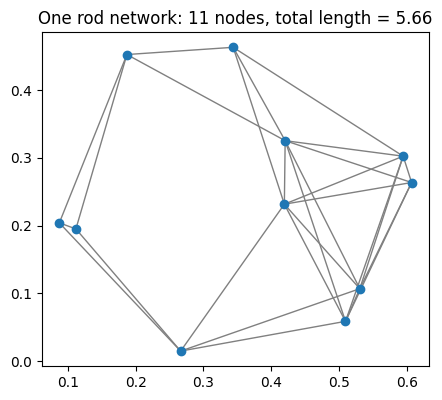

In [28]:
g = rod_graphs[0]
plt.figure(figsize=(5, 5))
for i, j in g.edge_index.t().tolist():
    if i < j:
        plt.plot(*zip(g.x[i].tolist(), g.x[j].tolist()), color="gray", linewidth=1)
plt.scatter(g.x[:, 0], g.x[:, 1], zorder=3)
plt.title(f"One rod network: {g.num_nodes} nodes, total length = {g.y_total.item():.2f}")
plt.gca().set_aspect("equal")
plt.show()

## 27. An edge-aware regressor

The targets depend on **edge lengths**, $\lVert\mathbf p_j-\mathbf p_i\rVert$. A GCN only sees node features, so we use the *difference message* from Tutorial 5, Exercise 7: each message is computed by a small MLP from $\mathbf p_j-\mathbf p_i$.

$$
\mathbf m_{j\rightarrow i}=\operatorname{MLP}\left(\mathbf p_j-\mathbf p_i\right),\qquad \mathbf h_i=\sum_{j\in\mathcal N(i)}\mathbf m_{j\rightarrow i}
$$

Using differences makes the model **translation-invariant**: shifting the whole network does not change the prediction, just as moving a truss does not change its total length.

In [29]:
from torch_geometric.nn import MessagePassing

class RelativePositionConv(MessagePassing):
    """Message = MLP(p_j - p_i), summed over neighbours."""
    def __init__(self, hidden_dim):
        super().__init__(aggr="add")
        self.mlp = nn.Sequential(nn.Linear(2, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, hidden_dim))

    def forward(self, pos, edge_index):
        return self.propagate(edge_index, pos=pos)

    def message(self, pos_i, pos_j):
        return self.mlp(pos_j - pos_i)

class GraphRegressor(nn.Module):
    def __init__(self, hidden_dim=64, readout="sum"):
        super().__init__()
        self.conv = RelativePositionConv(hidden_dim)
        self.readout = readout
        self.head = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, 1))

    def forward(self, x, edge_index, batch):
        h = self.conv(x, edge_index)                  # node embeddings
        h_graph = global_pool(h, batch, self.readout) # readout
        return self.head(h_graph).squeeze(-1)         # one number per graph

## 28. Train with sum and mean readouts on both targets

We standardise each target (subtract the training mean, divide by the training standard deviation), train with `MSELoss`, and report $R^2$ on the test graphs:

$$
R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}
$$

$R^2=1$ is a perfect fit; $R^2=0$ is no better than always predicting the mean.

In [30]:
rod_train, rod_val, rod_test = rod_graphs[:800], rod_graphs[800:1000], rod_graphs[1000:]

def train_regressor(target, readout, epochs=60, seed=0):
    torch.manual_seed(seed)
    y_train = torch.cat([getattr(g, target) for g in rod_train])
    mu, sigma = y_train.mean(), y_train.std()

    def loader(graphs, shuffle=False):
        return DataLoader(graphs, batch_size=64, shuffle=shuffle)

    @torch.no_grad()
    def predict(m, graphs):
        m.eval()
        preds, ys = [], []
        for b in loader(graphs):
            b = b.to(device)
            preds.append(m(b.x, b.edge_index, b.batch).cpu() * sigma + mu)
            ys.append(getattr(b, target).cpu())
        return torch.cat(preds), torch.cat(ys)

    def r2(pred, y):
        return 1 - ((y - pred) ** 2).sum().item() / ((y - y.mean()) ** 2).sum().item()

    m = GraphRegressor(hidden_dim=64, readout=readout).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=0.005)
    best_val, best_state = -float("inf"), None
    for _ in range(epochs):
        m.train()
        for b in loader(rod_train, shuffle=True):
            b = b.to(device)
            opt.zero_grad()
            y = (getattr(b, target) - mu.to(device)) / sigma.to(device)
            loss = F.mse_loss(m(b.x, b.edge_index, b.batch), y)
            loss.backward()
            opt.step()
        val = r2(*predict(m, rod_val))
        if val > best_val:
            best_val, best_state = val, copy.deepcopy(m.state_dict())
    m.load_state_dict(best_state)
    pred, y = predict(m, rod_test)
    return r2(pred, y), (y - pred).abs().mean().item(), m, (pred, y)

reg_results = {}
for target in ["y_total", "y_mean"]:
    for readout in ["sum", "mean"]:
        r2_test, mae, m, preds = train_regressor(target, readout)
        reg_results[(target, readout)] = (r2_test, mae, preds)
        print(f"target={target:8s} readout={readout:4s} | test R² = {r2_test:6.3f} | MAE = {mae:.4f}")

target=y_total  readout=sum  | test R² =  0.950 | MAE = 1.4564
target=y_total  readout=mean | test R² =  0.486 | MAE = 4.5485
target=y_mean   readout=sum  | test R² =  0.370 | MAE = 0.0057
target=y_mean   readout=mean | test R² =  0.957 | MAE = 0.0013


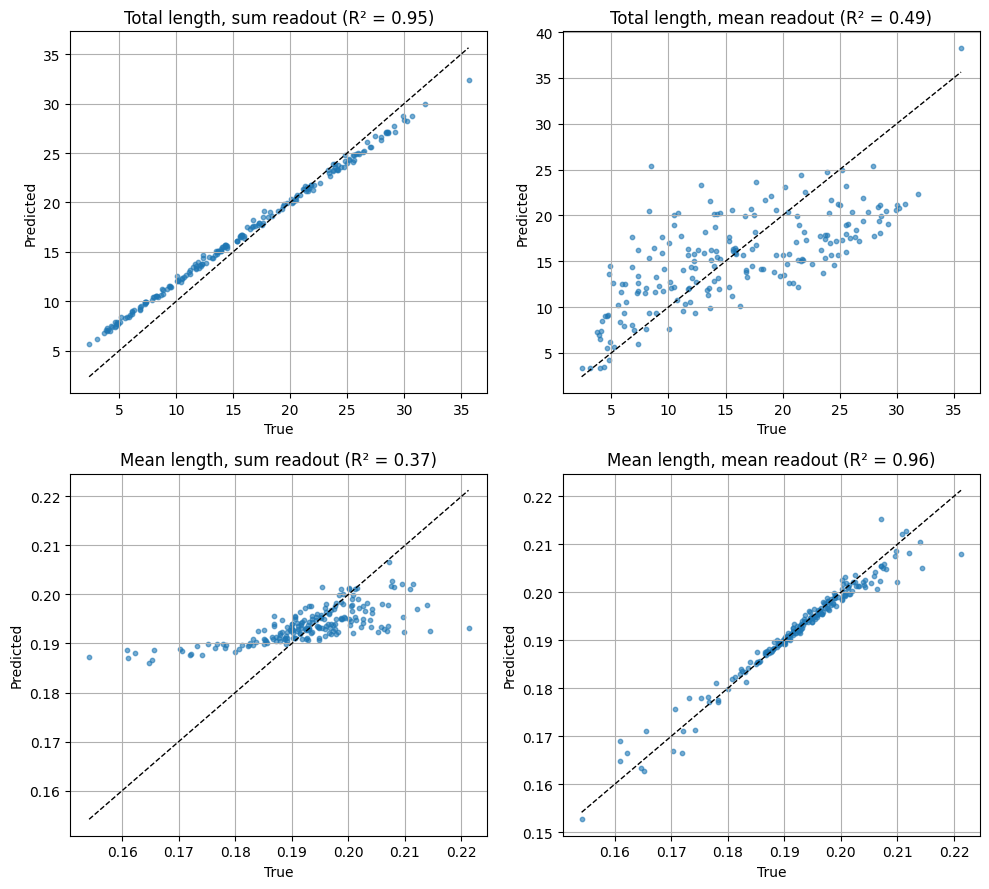

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for row, target in enumerate(["y_total", "y_mean"]):
    for col, readout in enumerate(["sum", "mean"]):
        r2_test, _, (pred, y) = reg_results[(target, readout)]
        ax = axes[row, col]
        ax.scatter(y, pred, s=10, alpha=0.6)
        lo, hi = y.min().item(), y.max().item()
        ax.plot([lo, hi], [lo, hi], "k--", linewidth=1)
        ax.set_title(f"{'Total' if target == 'y_total' else 'Mean'} length, {readout} readout (R² = {r2_test:.2f})")
        ax.set_xlabel("True")
        ax.set_ylabel("Predicted")
        ax.grid(True)
plt.tight_layout()
plt.show()

The pattern follows from what each readout keeps:

- **Total length (extensive):** every node contributes the lengths of its own edges, so the total is a **sum over nodes**. Sum readout matches this structure exactly. Mean readout divides by the number of nodes — information the head cannot recover — so it captures only part of the variation. (It does not fail completely: small networks have relatively more boundary nodes with fewer neighbours, which leaks a weak hint about size.)
- **Mean length (intensive):** the answer does not grow with size. Mean readout is naturally scale-free and fits it well. Sum readout produces vectors that grow with the number of nodes; the head would have to learn to divide the size back out, which an MLP does poorly.

Notice why we kept the point **density** constant. If all networks were squeezed into the same unit square, larger networks would also be denser, every node would see more neighbours, and the node embeddings would reveal the graph size — so even the mean readout could predict the total. Real datasets often contain such hidden shortcuts; it is worth checking for them.

$$
\boxed{\text{extensive target}\rightarrow\text{sum readout},\qquad\text{intensive target}\rightarrow\text{mean readout}}
$$

This is a useful rule of thumb for engineering quantities: total heat flow, total mass, or total drag force are extensive; average temperature, pressure coefficient, or stress concentration are intensive.

# 🧪 Hands-on Exercise 6 — Size extrapolation

Generate a test set of **larger** networks (80–120 nodes) and evaluate the trained models without retraining.

1. Which readout extrapolates better for the total length?
2. Why might even the sum readout fail on much larger graphs? (Hint: look at the MLP head — what happens to inputs far outside the training range?)

In [34]:
# TODO: test on larger graphs.

# torch.manual_seed(1)
# big_graphs = [random_rod_network(int(torch.randint(80, 121, (1,)))) for _ in range(200)]
# ...

# 🧪 Hands-on Exercise 7 — GCN on the rod networks

Train a `GraphGCN`-style regressor (two `GCNConv` layers, readout, head with 1 output) on the total-length target, using the coordinates as node features.

Why does it perform worse than `RelativePositionConv`? What information does a GCN layer not have access to?

In [35]:
# TODO: compare a GCN regressor with the edge-aware regressor.

# Part X — Hierarchical pooling and engineering meshes

## 29. Beyond global pooling

Global readouts collapse all nodes in **one step**. For large graphs with meaningful substructures — functional groups in a molecule, components in an assembly, regions in a mesh — this may discard too much.

**Hierarchical pooling** coarsens the graph gradually:

```text
 full graph  ──GNN──▶  coarsen  ──GNN──▶  coarsen  ──▶  readout
 (100 nodes)          (20 clusters)      (5 clusters)
```

One example is **DiffPool** (Ying et al., 2018). It learns a soft assignment matrix $\mathbf S$ that maps nodes to clusters, then builds a smaller graph:

$$
\mathbf X'=\mathbf S^{T}\mathbf Z,\qquad \mathbf A'=\mathbf S^{T}\mathbf A\mathbf S
$$

where $\mathbf Z$ are node embeddings and $\mathbf A$ is the adjacency matrix. DiffPool is powerful but uses dense matrices, so its memory grows quadratically with the number of nodes. Sparse alternatives such as **SAGPool** (Lee et al., 2019) keep a learned subset of nodes instead. PyG provides both (`dense_diff_pool`, `SAGPooling`).

On small graphs like MUTAG, simple global readouts are usually a strong baseline. Try them first.

## 30. Graph-level prediction for engineering meshes

| Graph-level concept | Engineering interpretation |
|---|---|
| One graph | one mesh, one geometry, or one simulated operating condition |
| Node embeddings | local state of each cell or vertex |
| Readout | integration or averaging over the domain |
| Sum readout | integral-like, for extensive quantities (total heat flow, total force) |
| Mean readout | average-like, for intensive quantities (mean temperature, $C_D$) |
| Graph-level target | pressure drop, drag coefficient, total heat transfer, peak stress |

A possible workflow:

1. Convert each simulation's mesh into a graph.
2. Node features: local fields (pressure, velocity, temperature) and geometry; edge features: distances, face areas, normals.
3. Message passing builds contextual node embeddings.
4. A readout summarises the whole domain.
5. A head predicts the global quantity.

Two cautions:

- **Sum readout is mesh-dependent.** Refining the mesh doubles the number of cells and roughly doubles a plain sum, even though the physical total is unchanged. A physically meaningful "integral" readout should weight each node by its **cell volume or area**: $\mathbf h_G=\sum_v V_v\,\mathbf h_v$.
- A graph-level prediction does not automatically respect conservation laws, boundary conditions, or dimensional consistency. Evaluate across mesh resolutions and operating conditions, not just on random splits of one dataset.

# 🚀 Final Challenge — Predict a global quantity from a mesh

Build a graph-level regression study inspired by heat transfer.

1. Generate $n\times n$ grid graphs (reuse `grid_graph` from Tutorial 7) for $n\in\{8, 12, 16\}$.
2. Give each node a random heat-source value $q_v$ and its coordinates.
3. Targets per graph:
   - **Total heat** $Q=\sum_v q_v\,\Delta A_v$ with cell area $\Delta A_v=1/n^2$ (extensive in the physical sense, but mesh-independent).
   - **Peak source** $\max_v q_v$ (intensive).
4. Train on $n=8$ and $n=12$, test on $n=16$.

Compare readouts:

| Readout | Total heat — test R² ($n=16$) | Peak source — test R² ($n=16$) |
|---|---:|---:|
| Sum | ? | ? |
| Mean | ? | ? |
| Max | ? | ? |
| Area-weighted sum $\sum_v\Delta A_v\mathbf h_v$ | ? | ? |

Questions:
- Why does a plain sum readout fail when the mesh is refined, even though the physical total heat is mesh-independent?
- Which readout matches the peak source? Why?
- How would you pass the cell area to the readout?

### Completion checklist

- [ ] I can explain the difference between node-, edge-, and graph-level tasks.
- [ ] I implemented sum, mean, and max readouts from scratch and verified them against PyG.
- [ ] I understand how PyG batches graphs and what the `batch` vector does.
- [ ] I trained a graph classifier on MUTAG and compared it with a majority and a bag-of-atoms baseline.
- [ ] I compared readouts over several random splits and reported mean ± standard deviation.
- [ ] I trained a graph regressor and can explain when to use sum vs. mean readout.
- [ ] I can describe how a readout relates to integration over a mesh.

# 31. Summary

We learned:
- how graph-level tasks differ from node- and edge-level tasks
- why a readout must be fixed-size and permutation-invariant
- how to implement sum, mean, and max readouts with `index_add_` and `scatter_reduce_`
- how PyG batches graphs into one disconnected graph with a `batch` vector
- how to train and evaluate a graph classifier on MUTAG
- why baselines and repeated splits are essential on small datasets
- how to turn a classifier into a regressor
- that sum readouts suit extensive quantities and mean readouts suit intensive ones
- how hierarchical pooling and area-weighted readouts extend these ideas to meshes

The key takeaway:

> A readout is just one more aggregation — over **all nodes of a graph** instead of over the neighbours of one node. Choose it the way you would choose an integral or an average for a physical quantity.

# 32. What comes next?

## Tutorial 9 — GNNs for Mesh-Based Systems

We now have every building block: message passing, attention, aggregation, sampling, and graph-level readout. In the next tutorial, we apply them to **computational meshes**:

```text
mesh (cells, faces, vertices)
    ↓
graph (nodes, edges, node + edge features)
    ↓
geometry-aware message passing  (relative positions, distances, face normals)
    ↓
node-level fields  and  graph-level quantities
```

We will build graphs from meshes, add geometric edge features, and look closely at mesh resolution and generalisation.

---

## References and further reading

1. Xu, K. et al. (2019). [How Powerful are Graph Neural Networks?](https://arxiv.org/abs/1810.00826) ICLR.
2. Ying, Z. et al. (2018). [Hierarchical Graph Representation Learning with Differentiable Pooling](https://arxiv.org/abs/1806.08804). NeurIPS.
3. Lee, J. et al. (2019). [Self-Attention Graph Pooling](https://arxiv.org/abs/1904.08082). ICML.
4. Gilmer, J. et al. (2017). [Neural Message Passing for Quantum Chemistry](https://proceedings.mlr.press/v70/gilmer17a.html). ICML.
5. Debnath, A. K. et al. (1991). Structure-activity relationship of mutagenic aromatic and heteroaromatic nitro compounds. *J. Med. Chem.* 34(2). — the original MUTAG data.

- [PyG global pooling layers](https://pytorch-geometric.readthedocs.io/en/latest/modules/nn.html#pooling-layers)
- [PyG `TUDataset`](https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.datasets.TUDataset.html)
- [PyG `DataLoader`](https://pytorch-geometric.readthedocs.io/en/latest/modules/loader.html)

---

**Learn the graph. Understand the message passing. Build the model. Connect it to the physical world.**

*HalfQubiX · The Learning Stack*